We need to put some results for the department seminar presentation slide. Professor said I should make DO-Nutrient diagram and also T-S diagram with colored dots to show the DO value.

In [14]:
# Imports
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as colors
import sys
import os
import yaml
from pathlib import Path

# Resolve project root and add to sys.path
# Assuming notebook is in notebooks/pipeline/
current_dir = Path(os.getcwd()).resolve()
project_root = current_dir.parent.parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths

In [15]:
# Load the pre-processed data using the centralized ProjectPaths
merged_gdf = pd.read_feather(ProjectPaths.MERGED_DATA_FILE, use_threads=False)
merged_gdf = gpd.GeoDataFrame(
    merged_gdf, 
    geometry=gpd.points_from_xy(merged_gdf.longitude, merged_gdf.latitude), 
    crs='EPSG:4326'
)

# --- Dynamic Regional Filtering ---
try:
    with open(project_root / 'params.yaml', 'r') as f:
        params = yaml.safe_load(f)
    TARGET_REGION = params['mapping']['target_region']
    REGION_COLUMN = params['mapping']['region_column']
    
    # Apply filtering
    initial_count = len(merged_gdf)
    merged_gdf = merged_gdf[merged_gdf[REGION_COLUMN] == TARGET_REGION].copy()
    print(f"Region: {TARGET_REGION} ({len(merged_gdf)} rows, {initial_count - len(merged_gdf)} filtered out)")
except Exception as e:
    print(f"Regional filtering failed: {e}. Processing full dataset.")
# ---------------------------------

# Filter summer bottom DO data
summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Summer') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(summer_bottom_df.head())

Region: Seto Inland Sea (42326 rows, 20412 filtered out)
       uniqueid zettaicode locationna wancode prefectuei  watercode renban  \
268  0000001734   00002811      兵庫県11      03         28        301     11   
276  0000001742   00002823      兵庫県23      03         28        301     23   
283  0000001678   00000272       大阪府2      03         27        301      2   
291  0000001686   00000275       大阪府5      03         27        301      5   
299  0000001694   00002725      大阪府25      03         27        301     25   

     nendo  survey_ym  surveyyear  ...  doc  doc2  dataflag  scale  \
268   1981 1981-06-01        1981  ...  0.0   0.0         1     -1   
276   1981 1981-06-01        1981  ...  0.0   0.0         1     -1   
283   1981 1981-06-01        1981  ...  0.0   0.0         1     -1   
291   1981 1981-06-01        1981  ...  0.0   0.0         1     -1   
299   1981 1981-06-01        1981  ...  0.0   0.0         1     -1   

                       geometry  year   watermass_nam

In [16]:
print(summer_bottom_df['division'].unique())
print(summer_bottom_df.columns)

['Osaka Bay' 'Harima Nada' 'Iyo Nada' 'Suo Nada' 'Bisan Seto' 'Bingo Nada'
 'Bungo Channel' 'Hibiki Nada' 'Kii Channel' 'Aki Nada' 'Hiroshima Bay'
 'Hiuchi Nada']
Index(['uniqueid', 'zettaicode', 'locationna', 'wancode', 'prefectuei',
       'watercode', 'renban', 'nendo', 'survey_ym', 'surveyyear', 'surveymont',
       'surveyday', 'surveyhour', 'surveymini', 'saisuipoin', 'latitude',
       'longitude', 'weather', 'cloud', 'fuko', 'fusoku', 'temp', 'color',
       'saisuidept', 'depth', 'clearness', 'wtemp', 'ph', 'ph2', 'do_', 'do_2',
       'salt', 'salt2', 'cod', 'cod2', 'rcod', 'rcod2', 'nh4n', 'nh4n2',
       'no2n', 'no2n2', 'no3n', 'no3n2', 'tn', 'tn2', 'po4p', 'po4p2', 'tp',
       'tp2', 'chlorophyl', 'chloroph_1', 'feiochin', 'feiochin2', 'toc',
       'toc2', 'doc', 'doc2', 'dataflag', 'scale', 'geometry', 'year',
       'watermass_name', 'division', 'details', 'season'],
      dtype='object')


Valid rows for T-S plot: 5376
S range: 0.00 - 39.74 PSU
T range: 12.60 - 29.80 °C
DO range: 0.00 - 12.00 mg/L


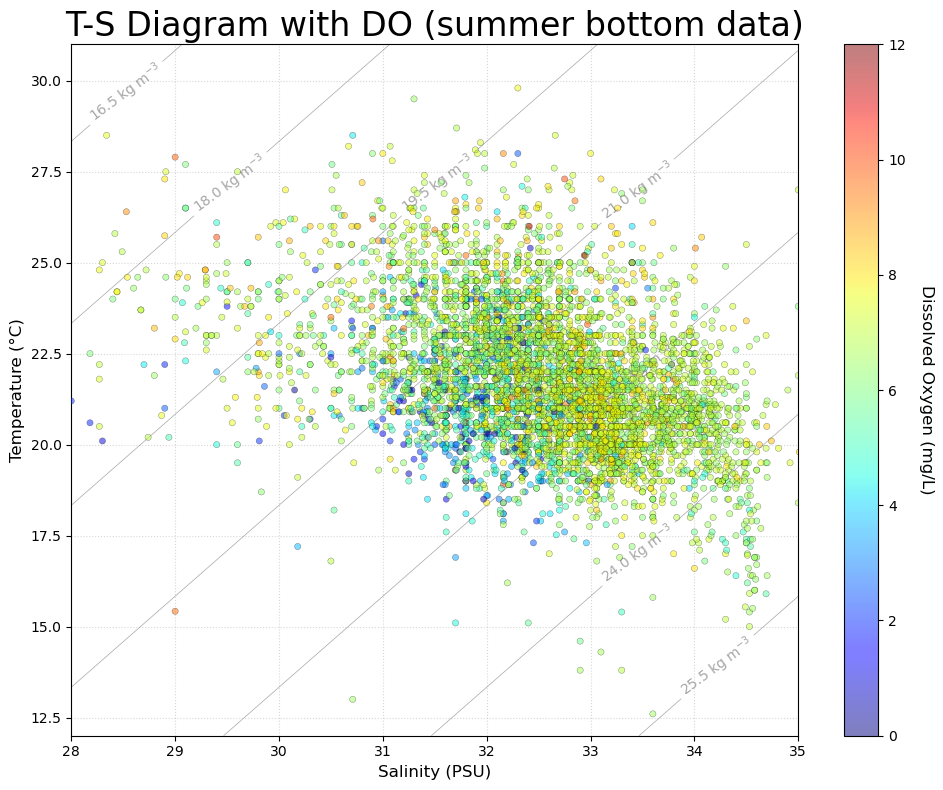

In [17]:
# --- STEP 1: Define the Density Calculation Function ---
# This linear approximation is standard for visualizing "Isopycnals" 
# within standard ranges (10-30°C, 25-35 PSU).
def calculate_density(T, S):
    return (0.75 * S) - (0.3 * T) + 4.0

# --- STEP 2: Prepare Data & Grid ---
# Safe numeric conversion (follow repo pattern: convert before aggregation)
S = pd.to_numeric(summer_bottom_df['salt'], errors='coerce').dropna()
T = pd.to_numeric(summer_bottom_df['wtemp'], errors='coerce').dropna()
DO = pd.to_numeric(summer_bottom_df['do_'], errors='coerce').dropna()

# Align indices after dropna (remove rows where any of S, T, DO is NaN)
valid_idx = S.index.intersection(T.index).intersection(DO.index)
S = S.loc[valid_idx]
T = T.loc[valid_idx]
DO = DO.loc[valid_idx]

if len(S) == 0:
    raise ValueError("No valid S, T, DO data after coercion. Check column names and data types.")

print(f"Valid rows for T-S plot: {len(S)}")
print(f"S range: {S.min():.2f} - {S.max():.2f} PSU")
print(f"T range: {T.min():.2f} - {T.max():.2f} °C")
print(f"DO range: {DO.min():.2f} - {DO.max():.2f} mg/L")

# Set manual limits for better visualization
s_min, s_max = 28.0, 35.0   # Salinity: Ignore the low outliers < 28
t_min, t_max = 12.0, 31.0   # Temperature: Focus on 12-31°C

# Create a background grid for the grey lines
s_grid = np.linspace(s_min, s_max, 100)
t_grid = np.linspace(t_min, t_max, 100)
S_grid, T_grid = np.meshgrid(s_grid, t_grid)
Sigma_grid = calculate_density(T_grid, S_grid)

# --- STEP 3: Create the Plot ---
plt.figure(figsize=(10, 8))

# A. Draw the Grey Isopycnals (Density Lines)
# We plot contours every 0.5 or 1.0 unit of density
contours = plt.contour(S_grid, T_grid, Sigma_grid, 
                       colors='grey', linestyles='-', linewidths=0.5, alpha=0.7)
plt.clabel(contours, inline=True, fontsize=10, fmt=r'%1.1f kg m$^{-3}$') # Labels the lines

# B. Draw the Scatter Points (Colored by DO)
sc = plt.scatter(S, T, c=DO, cmap='jet', s=20, edgecolors='k', linewidth=0.3, alpha=0.5, zorder=5)

# C. Add Colorbar & Labels
cbar = plt.colorbar(sc)
cbar.set_label('Dissolved Oxygen (mg/L)', rotation=270, labelpad=20, fontsize=12)

plt.xlabel('Salinity (PSU)', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.title('T-S Diagram with DO (summer bottom data)', fontsize=24)

# Apply the calculated limits
plt.xlim(s_min, s_max)
plt.ylim(t_min, t_max)
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [18]:
# Make another plot for winter bottom data

# Filter winter bottom do data
winter_bottom_df = merged_gdf[
    (merged_gdf['season'] == 'Winter') &
    (merged_gdf['saisuipoin'] == 2)
].dropna(subset=['do_']).copy()

print(winter_bottom_df.head())
# print(winter_bottom_df['division'].unique())
# print(winter_bottom_df.columns)

       uniqueid zettaicode locationna wancode prefectuei  watercode renban  \
270  0000001736   00002811      兵庫県11      03         28        301     11   
285  0000001680   00000272       大阪府2      03         27        301      2   
293  0000001688   00000275       大阪府5      03         27        301      5   
301  0000001744   00002823      兵庫県23      03         28        301     23   
302  0000001696   00002725      大阪府25      03         27        301     25   

     nendo  survey_ym  surveyyear  ...  doc  doc2  dataflag  scale  \
270   1981 1981-12-01        1982  ...  0.0   0.0         1     -1   
285   1981 1981-12-01        1982  ...  0.0   0.0         1     -1   
293   1981 1981-12-01        1982  ...  0.0   0.0         1     -1   
301   1981 1981-12-01        1982  ...  0.0   0.0         1     -1   
302   1981 1981-12-01        1982  ...  0.0   0.0         1     -1   

                       geometry  year   watermass_name   division  \
270    POINT (135.33056 34.695)  1981  Se

Valid rows for T-S plot: 5348
S range: 0.00 - 35.12 PSU
T range: 5.50 - 21.10 °C
DO range: 0.00 - 13.00 mg/L


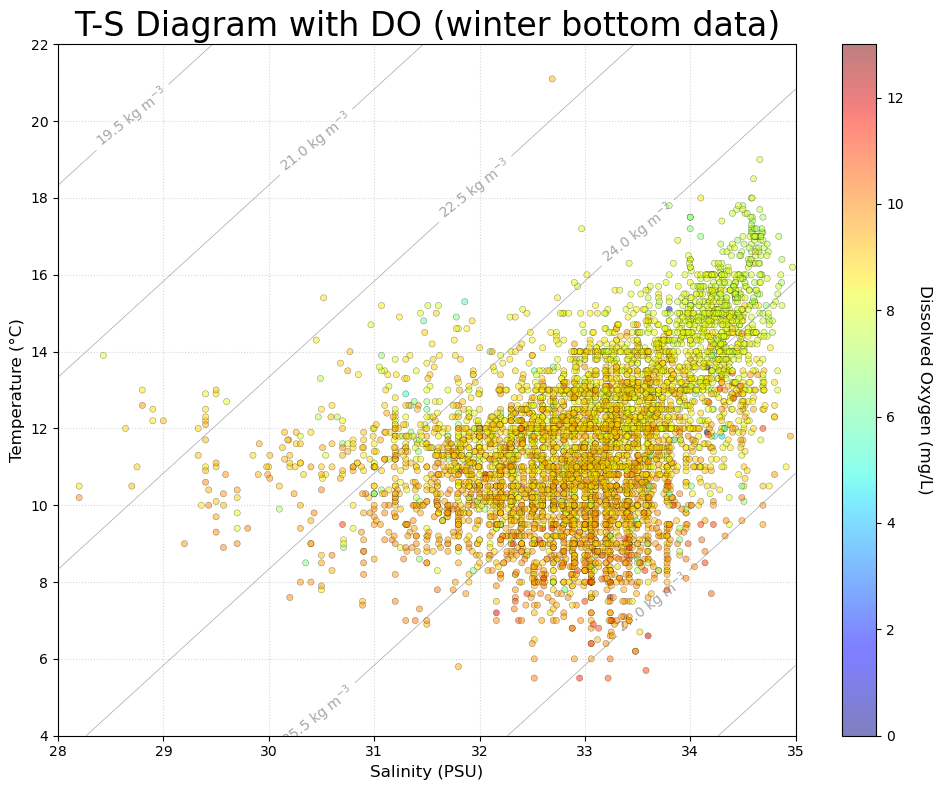

In [19]:
# Plot the winter bottom T-S diagram with DO

# --- STEP 1: Define the Density Calculation Function ---
# This linear approximation is standard for visualizing "Isopycnals" 
# within standard ranges (10-30°C, 25-35 PSU).
def calculate_density(T, S):
    return (0.75 * S) - (0.3 * T) + 4.0

# --- STEP 2: Prepare Data & Grid ---
# Safe numeric conversion (follow repo pattern: convert before aggregation)
S = pd.to_numeric(winter_bottom_df['salt'], errors='coerce').dropna()
T = pd.to_numeric(winter_bottom_df['wtemp'], errors='coerce').dropna()
DO = pd.to_numeric(winter_bottom_df['do_'], errors='coerce').dropna()

# Align indices after dropna (remove rows where any of S, T, DO is NaN)
valid_idx = S.index.intersection(T.index).intersection(DO.index)
S = S.loc[valid_idx]
T = T.loc[valid_idx]
DO = DO.loc[valid_idx]

if len(S) == 0:
    raise ValueError("No valid S, T, DO data after coercion. Check column names and data types.")

print(f"Valid rows for T-S plot: {len(S)}")
print(f"S range: {S.min():.2f} - {S.max():.2f} PSU")
print(f"T range: {T.min():.2f} - {T.max():.2f} °C")
print(f"DO range: {DO.min():.2f} - {DO.max():.2f} mg/L")

# Set manual limits for better visualization
s_min, s_max = 28.0, 35.0   
t_min, t_max = 4.0, 22.0   # lower range for denser cold water

# Create a background grid for the grey lines
s_grid = np.linspace(s_min, s_max, 100)
t_grid = np.linspace(t_min, t_max, 100)
S_grid, T_grid = np.meshgrid(s_grid, t_grid)
Sigma_grid = calculate_density(T_grid, S_grid)

# --- STEP 3: Create the Plot ---
plt.figure(figsize=(10, 8))

# A. Draw the Grey Isopycnals (Density Lines)
# We plot contours every 0.5 or 1.0 unit of density
contours = plt.contour(S_grid, T_grid, Sigma_grid, 
                       colors='grey', linestyles='-', linewidths=0.5, alpha=0.7)
plt.clabel(contours, inline=True, fontsize=10, fmt=r'%1.1f kg m$^{-3}$') # Labels the lines

# B. Draw the Scatter Points (Colored by DO)
sc = plt.scatter(S, T, c=DO, cmap='jet', s=20, edgecolors='k', linewidth=0.3, alpha=0.5, zorder=5)

# C. Add Colorbar & Labels
cbar = plt.colorbar(sc)
cbar.set_label('Dissolved Oxygen (mg/L)', rotation=270, labelpad=20, fontsize=12)

plt.xlabel('Salinity (PSU)', fontsize=12)
plt.ylabel('Temperature (°C)', fontsize=12)
plt.title('T-S Diagram with DO (winter bottom data)', fontsize=24)

# Apply the calculated limits
plt.xlim(s_min, s_max)
plt.ylim(t_min, t_max)
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()